<a href="https://colab.research.google.com/github/Dan-KM/is-project-2/blob/main/app/model/colab/Irrigation_prediction_model_training.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Irrigation Prediction model training

### Env Setup

In [1]:
%pip install ipykernel

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 16.5 MB/s  0:00:00


In [2]:
import sys
print(sys.executable)

/usr/bin/python3


In [3]:
%pip install python-dotenv

In [4]:
import os
from dotenv import load_dotenv

# This loads .env from the current (or parent) directory if present
# `override=True` ensures that the values set in the .env file take precedence
# over any existing environment variables set in the Operating System
load_dotenv(override=True)

def resolve_environment():
    if os.environ.get("ENVIRONMENT"):
        return os.environ["ENVIRONMENT"].upper()

    # Automatic detection if running in Google Colab
    if "google.colab" in sys.modules:
        return "COLAB"

    # Defaults to a 'DEV' environment if it is not set
    return "DEV"

ENV_SETUP = resolve_environment()

VALID_ENVIRONMENTS = {"PROD", "STAGING", "TESTING", "COLAB", "DEV"}

if ENV_SETUP not in VALID_ENVIRONMENTS:
    print(f"Warning: Invalid ENVIRONMENT '{ENV_SETUP}'. Defaulting to 'DEV'.")
    ENV_SETUP = "DEV"

print(f"Dependencies will be installed for a '{ENV_SETUP}' environment.")

Dependencies will be installed for a 'COLAB' environment.


In [5]:
import sys
import subprocess

def silent_pip_install(args):
    """
    Used to run a command quietly and
    only shows an error if something went wrong.
    :param args: Array of arguments that form the command.
    :return:
    """

    # `sys.executable` is added to ensure you are installing into the virtual environment
    cmd = [sys.executable, "-m", "pip", *args]
    # `subprocess.run` is used to execute an external command
    # `stdout=subprocess.PIPE` captures normal output into result.stdout
    # `stderr=subprocess.PIPE` captures error output into result.stderr
    # `text=True` decodes output as strings (str) instead of bytes, so you can print/read it directly.
    result = subprocess.run(cmd, stdout=subprocess.PIPE, stderr=subprocess.PIPE, text=True)
    # `result.returncode` is the process exit status. 0 means success.
    if result.returncode != 0:
        print(result.stderr)

if ENV_SETUP == "PROD":
    silent_pip_install([
        "install", "-r",
        "https://raw.githubusercontent.com/course-files/RegressionAndClassification//refs/heads/main/requirements/prod.txt"
    ])
    print(f"Completed installation of environment dependencies for '{ENV_SETUP}'.")

elif ENV_SETUP in {"STAGING"}:
    silent_pip_install([
        "install", "-r",
        "https://raw.githubusercontent.com/course-files/RegressionAndClassification//refs/heads/main/requirements/dev.txt",
        "-c", "https://raw.githubusercontent.com/course-files/RegressionAndClassification//refs/heads/main/requirements/constraints.txt"
    ])
    print(f"Completed installation of environment dependencies for '{ENV_SETUP}'.")

elif ENV_SETUP in {"TESTING"}:
    silent_pip_install([
        "install", "-r",
        "https://raw.githubusercontent.com/course-files/RegressionAndClassification//refs/heads/main/requirements/dev.txt",
        "-c", "https://raw.githubusercontent.com/course-files/RegressionAndClassification//refs/heads/main/requirements/constraints.txt"
    ])
    print(f"Completed installation of environment dependencies for '{ENV_SETUP}'.")

elif ENV_SETUP in {"COLAB"}:
    silent_pip_install([
        "install", "-r",
        "https://raw.githubusercontent.com/course-files/RegressionAndClassification//refs/heads/main/requirements/colab.txt"
    ])
    print(f"Completed installation of environment dependencies for '{ENV_SETUP}'.")

elif ENV_SETUP in {"DEV"}:
    silent_pip_install([
        "install", "-r",
        "https://raw.githubusercontent.com/course-files/RegressionAndClassification//refs/heads/main/requirements/dev.txt",
        "-c", "https://raw.githubusercontent.com/course-files/RegressionAndClassification//refs/heads/main/requirements/constraints.txt"
    ])
    print(f"Completed installation of environment dependencies for '{ENV_SETUP}'.")

Completed installation of environment dependencies for 'COLAB'.


In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

pd.set_option("display.max_columns", None)
sns.set_style("whitegrid")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# For suppressing warnings displayed in the notebook
import warnings
warnings.filterwarnings('ignore')

print("The environment ready.")

The environment ready.


### Load Data

In [7]:
# @title
# For file and system operations
import urllib.request
import os

dataset_path = './data/Irrigation_Scheduling_Dataset.csv'
url = 'https://raw.githubusercontent.com/Dan-KM/is-project-2/refs/heads/main/dataset/Irrigation_Scheduling_Dataset.csv'

if not os.path.exists(dataset_path):
    print("Downloading dataset...")
    if not os.path.exists('./data'):
        os.makedirs('./data')
    urllib.request.urlretrieve(url, dataset_path)
    print("✅ Dataset downloaded")
else:
    print("✅ Dataset already exists locally")

use_cols = ['applicant_id','sector','county','quarter','loan_purpose','owner_education_level','business_age_years','num_employees','monthly_revenue_kes','loan_amount_kes','loan_term_months','interest_rate_pct','collateral_value_kes','debt_to_income_ratio','credit_score','num_previous_loans','missed_payments_count','online_presence_score','customer_satisfaction_score','competitor_density','credit_risk_category']
df = pd.read_csv(dataset_path, encoding='utf-8')

df.head()

✅ Dataset downloaded


,Field_ID,Crop_Type,Growth_Stage,Soil_Type,Day_of_Year,Time_of_Day,Soil_Moisture,Soil_Temperature,Soil_pH,Soil_EC,Ambient_Temperature,Relative_Humidity,Wind_Speed,Solar_Radiation,Rainfall_24h,Rainfall_Forecast_24h,Root_Zone_Depth,Leaf_Area_Index,Crop_Coefficient,Field_Slope,Water_Availability,Previous_Irrigation_Amount,Days_Since_Last_Irrigation,Historical_Soil_Moisture,Evaporation_Demand,Water_Stress_Index,Irrigation_Action
0,52,Wheat,Flowering,Clay,306,16,34.653372,28.475039,7.22,1.63,25.162077,75.883860,2.059025,617.894746,1.66,11.78,35.23,4.19,1.15,4.86,65.38,10.50,7,24.66,52.41,76.23,Medium
1,93,Rice,Maturity,Sandy,89,13,33.868557,23.155641,6.57,1.28,26.570275,88.786710,0.149411,459.057124,0.07,8.59,45.76,1.52,0.75,6.56,27.17,43.60,3,29.82,36.76,72.15,High
2,15,Groundnut,Fruiting,Clay,155,14,42.952956,23.344024,7.57,2.21,33.783657,75.959237,3.395399,456.585275,1.43,34.49,49.14,3.94,1.05,7.16,79.06,12.54,10,40.47,43.20,71.10,No_Irrigation
3,72,Wheat,Vegetative,Loamy,233,14,34.452554,29.874891,7.20,1.00,28.060771,71.470308,2.169183,583.682496,17.07,1.70,21.74,3.47,0.90,7.37,82.31,12.90,12,22.52,45.19,72.61,Medium
4,61,Sugarcane,Flowering,Sandy,193,14,20.163457,29.949118,6.24,1.78,25.205416,68.243676,5.644328,570.043475,2.72,2.86,45.94,4.41,1.15,5.16,77.28,4.12,11,15.32,50.08,93.57,High


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7000 entries, 0 to 6999
Data columns (total 27 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Field_ID                    7000 non-null   int64  
 1   Crop_Type                   7000 non-null   object 
 2   Growth_Stage                7000 non-null   object 
 3   Soil_Type                   7000 non-null   object 
 4   Day_of_Year                 7000 non-null   int64  
 5   Time_of_Day                 7000 non-null   int64  
 6   Soil_Moisture               6965 non-null   float64
 7   Soil_Temperature            6965 non-null   float64
 8   Soil_pH                     7000 non-null   float64
 9   Soil_EC                     7000 non-null   float64
 10  Ambient_Temperature         7000 non-null   float64
 11  Relative_Humidity           6965 non-null   float64
 12  Wind_Speed                  7000 non-null   float64
 13  Solar_Radiation             6965 

#### Target Identification

In [9]:
TARGET = "Irrigation_Action"

# `applicant_id` is an identifier, not a predictive feature. We will drop it
# but keep it in the raw (original) DataFrame in case we need to trace
# a specific row later.
print(f"Target variable: {TARGET}")
print(f"Classes: {sorted(df[TARGET].unique())}")
print(f"Number of predictor candidates (excluding IDs and the target): {df.shape[1] - 2}")

Target variable: Irrigation_Action
Classes: ['High', 'Low', 'Medium', 'No_Irrigation']
Number of predictor candidates (excluding IDs and the target): 25


## Initial EDA

### 1. Class count

In [10]:
class_counts = df[TARGET].value_counts()
# `normalize=True` returns proportions (fractions/percent share) instead of raw counts.
class_proportions = df[TARGET].value_counts(normalize=True).round(3)

class_summary = pd.DataFrame({"count": class_counts, "proportion": class_proportions})
class_summary

,count,proportion
Irrigation_Action,,
Medium,1750,0.25
High,1750,0.25
No_Irrigation,1750,0.25
Low,1750,0.25


From this we can tell that there is perfect balance among the different classes and there is exactly 25% observations for each case.

### 2. Distribution summary

In [11]:
numeric_cols = df.select_dtypes(include=[np.number]).drop(columns=["Field_ID"]).columns
categorical_cols = df.select_dtypes(exclude=[np.number, 'datetime64[ns]']).columns

print("\nThe identified numeric columns (measures) are:")
print(numeric_cols.tolist())

print("\nThe identified categorical columns (dimensions) are:")
print(categorical_cols.tolist())

q1 = df[numeric_cols].quantile(0.25)
q2 = df[numeric_cols].quantile(0.50)
q3 = df[numeric_cols].quantile(0.75)

iqr = q3 - q1

distribution_summary = pd.DataFrame({
    "min": df[numeric_cols].min(),
    "q1_25%": q1,
    "q2_50%": q2,
    "q3_75%": q3,
    "max": df[numeric_cols].max(),
    "mean": df[numeric_cols].mean(),
    "mode": df[numeric_cols].mode().iloc[0],
    "variance": df[numeric_cols].var(),
    "std_dev": df[numeric_cols].std(),
    "skewness": df[numeric_cols].skew(),
    "kurtosis": df[numeric_cols].kurt(),
    "IQR": iqr,
    "lower_fence": q1 - 1.5 * iqr,
    "upper_fence": q3 + 1.5 * iqr,
})

distribution_summary.round(2).style.format("{:,.2f}")


The identified numeric columns (measures) are:
['Day_of_Year', 'Time_of_Day', 'Soil_Moisture', 'Soil_Temperature', 'Soil_pH', 'Soil_EC', 'Ambient_Temperature', 'Relative_Humidity', 'Wind_Speed', 'Solar_Radiation', 'Rainfall_24h', 'Rainfall_Forecast_24h', 'Root_Zone_Depth', 'Leaf_Area_Index', 'Crop_Coefficient', 'Field_Slope', 'Water_Availability', 'Previous_Irrigation_Amount', 'Days_Since_Last_Irrigation', 'Historical_Soil_Moisture', 'Evaporation_Demand', 'Water_Stress_Index']

The identified categorical columns (dimensions) are:
['Crop_Type', 'Growth_Stage', 'Soil_Type', 'Irrigation_Action']


,min,q1_25%,q2_50%,q3_75%,max,mean,mode,variance,std_dev,skewness,kurtosis,IQR,lower_fence,upper_fence
Day_of_Year,1.00,88.00,181.00,272.00,365.00,180.43,189.00,"11,165.56",105.67,0.01,-1.20,184.00,-188.00,548.00
Time_of_Day,0.00,5.00,11.00,17.00,23.00,11.43,3.00,47.74,6.91,0.02,-1.21,12.00,-13.00,35.00
Soil_Moisture,7.90,29.30,34.99,40.40,64.83,34.63,7.90,69.35,8.33,-0.19,-0.09,11.11,12.63,57.07
Soil_Temperature,11.96,22.09,25.03,27.87,39.65,25.03,11.96,17.37,4.17,0.01,-0.16,5.78,13.43,36.54
Soil_pH,5.00,6.32,6.69,7.07,8.20,6.70,6.66,0.30,0.55,-0.02,-0.07,0.75,5.20,8.20
Soil_EC,0.25,0.96,1.26,1.57,2.78,1.26,0.25,0.20,0.45,0.06,-0.24,0.61,0.04,2.49
Ambient_Temperature,14.83,25.58,29.02,32.33,45.16,28.96,14.83,25.26,5.03,-0.01,-0.02,6.76,15.44,42.46
Relative_Humidity,44.69,69.75,75.20,80.46,98.08,75.17,44.69,61.95,7.87,-0.02,-0.07,10.71,53.69,96.53
Wind_Speed,-0.02,1.86,3.20,4.96,15.13,3.72,-0.02,6.34,2.52,1.31,2.24,3.11,-2.80,9.62
Solar_Radiation,49.74,399.61,521.75,642.95,950.23,519.71,49.74,"32,077.78",179.10,-0.04,-0.26,243.34,34.60,"1,007.96"


### 3. Checking Outliers

In [12]:
# Identify values below the lower fence or above the upper fence
# These are statistically considered as outliers
outlier_mask = (
    (df[numeric_cols] < q1 - 1.5 * iqr) |
    (df[numeric_cols] > q3 + 1.5 * iqr)
)

# Record features that contain at least one potential outlier
# Check each row (axis=1): True if the row contains an outlier in any numeric
# column
outliers = df[outlier_mask.any(axis=1)]

outlier_counts = outlier_mask.sum().rename("outlier_count").to_frame()

outlier_counts

,outlier_count
Day_of_Year,0
Time_of_Day,0
Soil_Moisture,46
Soil_Temperature,33
Soil_pH,45
Soil_EC,21
Ambient_Temperature,64
Relative_Humidity,39
Wind_Speed,217
Solar_Radiation,0


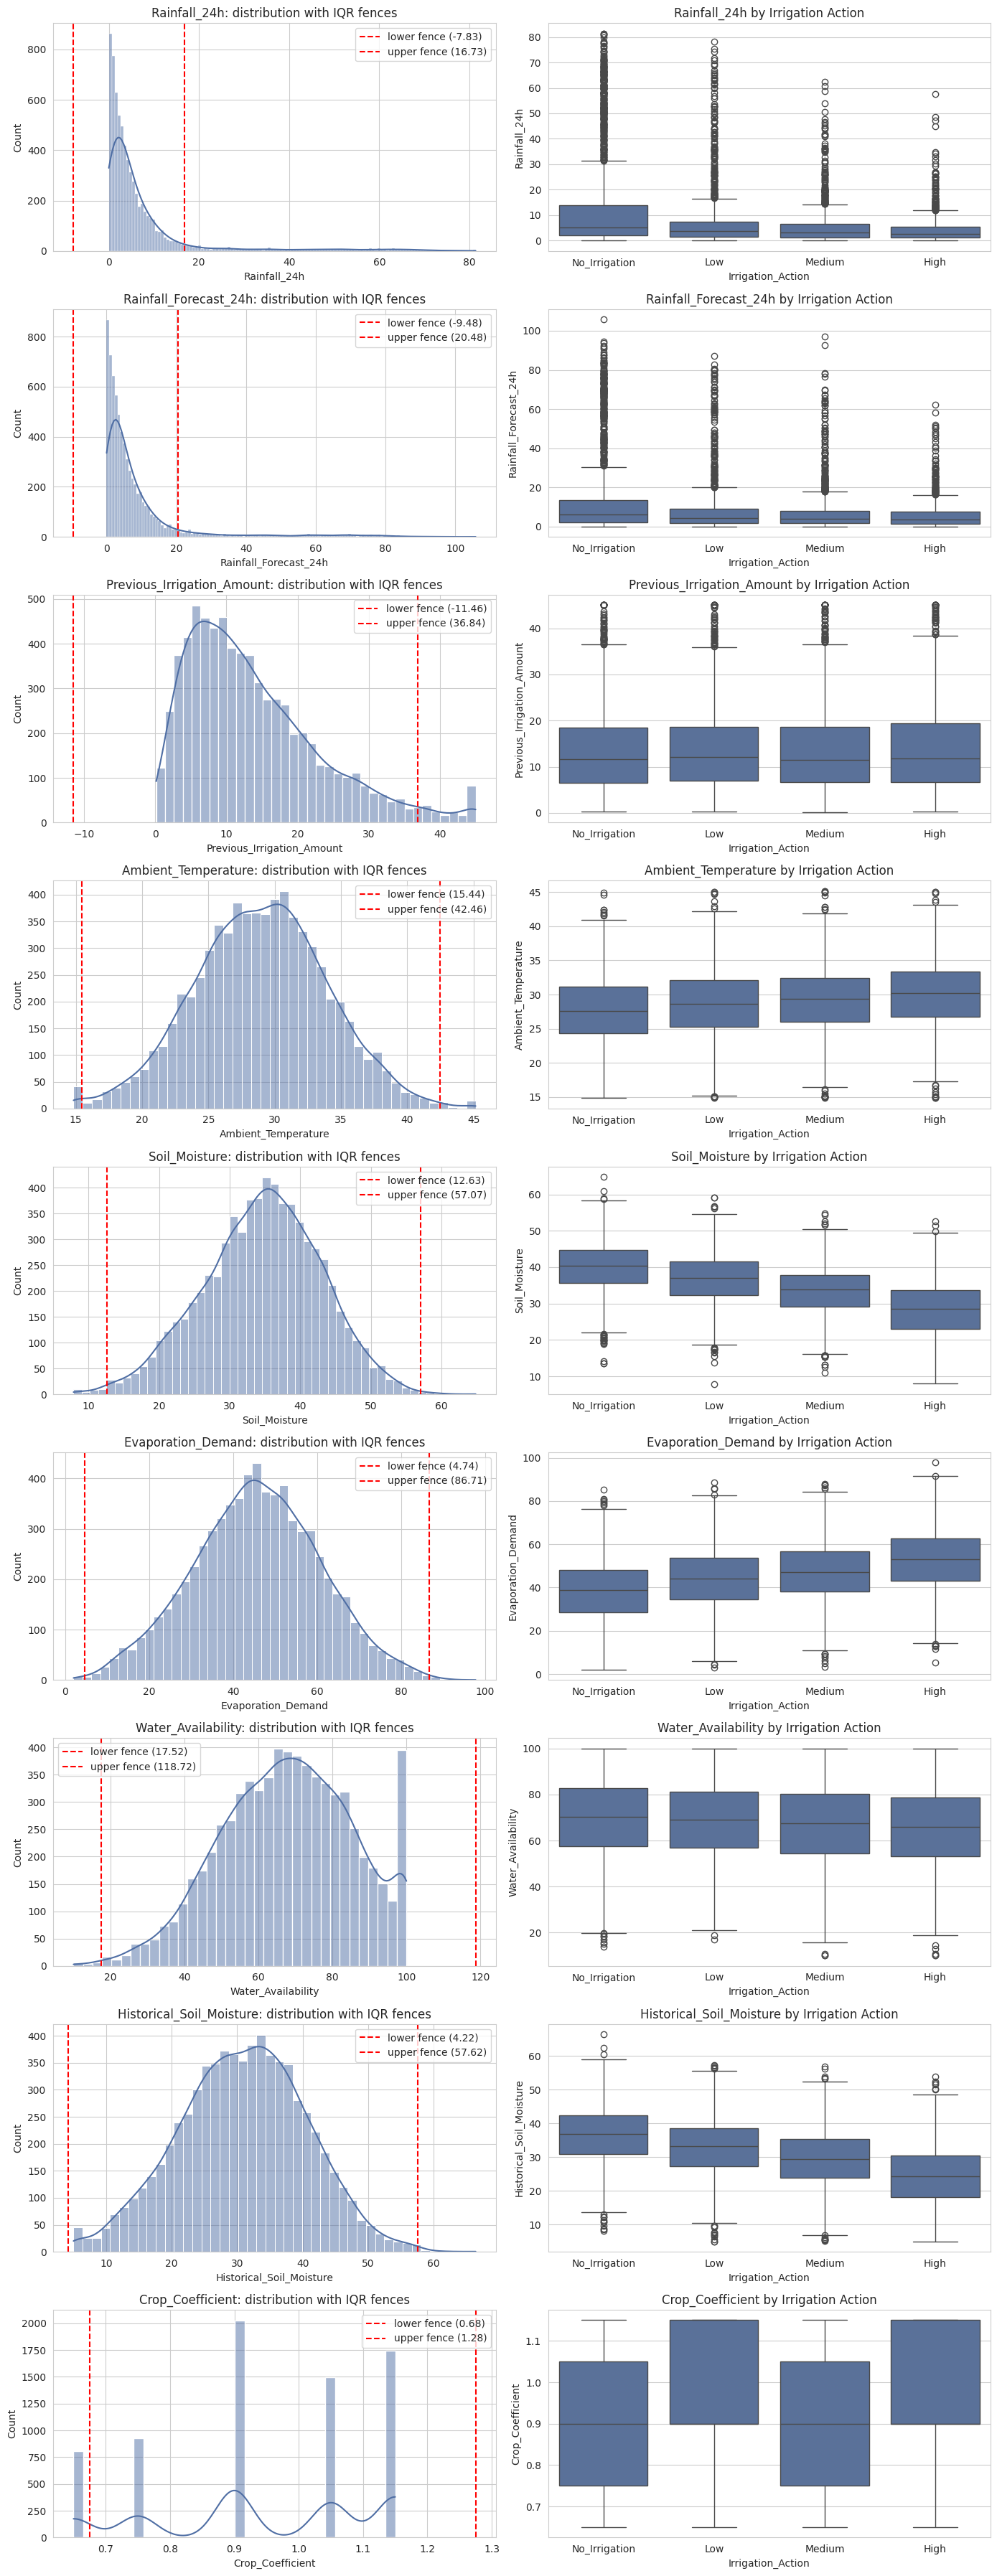

In [13]:
# Columns with flagged outliers (Days_Since_Last_Irrigation has 0, so it's skipped)
outlier_cols = ["Rainfall_24h", "Rainfall_Forecast_24h", "Previous_Irrigation_Amount",
                "Ambient_Temperature", "Soil_Moisture", "Evaporation_Demand",
                "Water_Availability", "Historical_Soil_Moisture", "Crop_Coefficient"]
class_order = ["No_Irrigation", "Low", "Medium", "High"]

fig, axes = plt.subplots(len(outlier_cols), 2, figsize=(14, 4 * len(outlier_cols)))

for i, col in enumerate(outlier_cols):
    lower_fence = q1[col] - 1.5 * iqr[col]
    upper_fence = q3[col] + 1.5 * iqr[col]

    # Left: distribution with the IQR fences marked
    sns.histplot(df[col], kde=True, ax=axes[i, 0], color="#4F6EA4")
    axes[i, 0].axvline(lower_fence, color="red", linestyle="--", label=f"lower fence ({lower_fence:.2f})")
    axes[i, 0].axvline(upper_fence, color="red", linestyle="--", label=f"upper fence ({upper_fence:.2f})")
    axes[i, 0].set_title(f"{col}: distribution with IQR fences")
    axes[i, 0].legend()

    # Right: boxplot per irrigation action -- are the outliers tied to a class?
    sns.boxplot(data=df, x=TARGET, y=col, order=class_order, ax=axes[i, 1], color="#4F6EA4")
    axes[i, 1].set_title(f"{col} by Irrigation Action")

plt.tight_layout()
plt.show()

Besides some features being heavily skewed, the outliers still look normal

### 4. Measures of Relationship


#### 4.1 The Analysis of Variance (ANOVA) F-statistic

**The Analysis of Variance (ANOVA) F-statistic tests whether the mean of a
numeric predictor differs significantly across several target classes.**
It works by comparing the variance between class groups to the variance
within each class group.

It requires data that does not contain missing values; therefore, we use a
simple median data imputation.

**Interpreting the F-statistic and p-value:**

**F-statistic:** Measures how much a feature's mean differs across the target
classes relative to variation within each class. **A higher value indicates
stronger separation between classes; a value near zero indicates little
separation.** We prioritize features with a high ANOVA F-statistic as strong
considerations for the model and give it closer attention during feature
selection.

**p-value:** The probability of observing the F-statistic (or a larger one)
if the feature had no real relationship with the target. A value **below 0.05**
is generally taken as evidence of a genuine association; a higher value
suggests the difference could be due to chance.

This test detects only linear separation between group means and does not
account for interactions between features. It is used as an initial screen,
not a final decision.

In [14]:
from sklearn.feature_selection import f_classif

numeric_predictors = df[numeric_cols].copy()
# Temporary median fill purely for this diagnostic (not the pipeline imputation)
numeric_predictors_filled = numeric_predictors.fillna(numeric_predictors.median())

f_stats, p_values = f_classif(numeric_predictors_filled, df[TARGET])
anova_summary = pd.DataFrame({
    "feature (numeric predictors)": numeric_cols,
    "F_statistic": f_stats,
    "p_value": p_values
}).sort_values("F_statistic", ascending=False)
anova_summary.round(4)

,feature (numeric predictors),F_statistic,p_value
21,Water_Stress_Index,1904.0791,0.0000
2,Soil_Moisture,865.3713,0.0000
19,Historical_Soil_Moisture,617.1364,0.0000
20,Evaporation_Demand,317.5209,0.0000
10,Rainfall_24h,238.3719,0.0000
9,Solar_Radiation,236.7714,0.0000
11,Rainfall_Forecast_24h,139.1866,0.0000
6,Ambient_Temperature,69.0100,0.0000
7,Relative_Humidity,41.6727,0.0000
16,Water_Availability,17.5446,0.0000


#### 4.2 Cramer's V

It measures the strength of association between a categorical
predictor and the categorical target, based on the chi-square statistic.

**Range:** From 0 to 1, regardless of the number of categories in
either variable, which makes it comparable across different categorical
features.

**Interpretation of magnitude:**
- **0.00 – 0.10:** Negligible association
- **0.10 – 0.20:** Weak association
- **0.20 – 0.40:** Moderate association
- **0.40 and above:** Strong association


In [15]:
# Cramer's V: association strength between categorical predictors and the target
def cramers_v(confusion_matrix):
    # A contingency table is a grid that displays the count of observations
    # for every combination of two categorical variables. Each row represents
    # a category of one variable, each column represents a category of the
    # other, and each cell holds the number of observations that fall into
    # that particular row-column combination.
    chi2 = stats.chi2_contingency(confusion_matrix)[0]   # chi-square statistic for the contingency table
    n = confusion_matrix.sum().sum()                     # total number of observations
    phi2 = chi2 / n                                       # normalize chi-square by sample size
    r, k = confusion_matrix.shape                         # r = number of rows (categories in predictor), k = number of columns (categories in target)

    # Bias correction (Bergsma's correction), since phi2, r, and k tend to overestimate association in small samples
    phi2_corrected = max(0, phi2 - ((k - 1) * (r - 1)) / (n - 1))
    r_corrected = r - ((r - 1) ** 2) / (n - 1)
    k_corrected = k - ((k - 1) ** 2) / (n - 1)

    # Final Cramer's V, bounded between 0 and 1
    return np.sqrt(phi2_corrected / min(k_corrected - 1, r_corrected - 1))

categorical_cols = [col for col in categorical_cols if col != TARGET]
cramers_v_results = {}

for col in categorical_cols:
    # Build a contingency table: counts of each category vs. each target class
    contingency = pd.crosstab(df[col], df[TARGET])
    cramers_v_results[col] = cramers_v(contingency.values)

# print("Example of a contingency table built for Cramer's V input:")
# print(contingency)

# Collect results into a single table, sorted so the strongest associations appear first
cramers_v_df = (
    pd.DataFrame.from_dict(
        cramers_v_results,
        orient="index",
        columns=["Cramers_V"]
    )
    .rename_axis("feature (categorical)")
    .reset_index()
)

cramers_v_df = cramers_v_df.sort_values(
    "Cramers_V",
    ascending=False
).round(3)

cramers_v_df

,feature (categorical),Cramers_V
2,Soil_Type,0.219
0,Crop_Type,0.031
1,Growth_Stage,0.012


`Soil_Type` has the higher values of Cramers_V but it being 0.219 is still considered as a weak association.

#### 4.3 Correlation Matrix

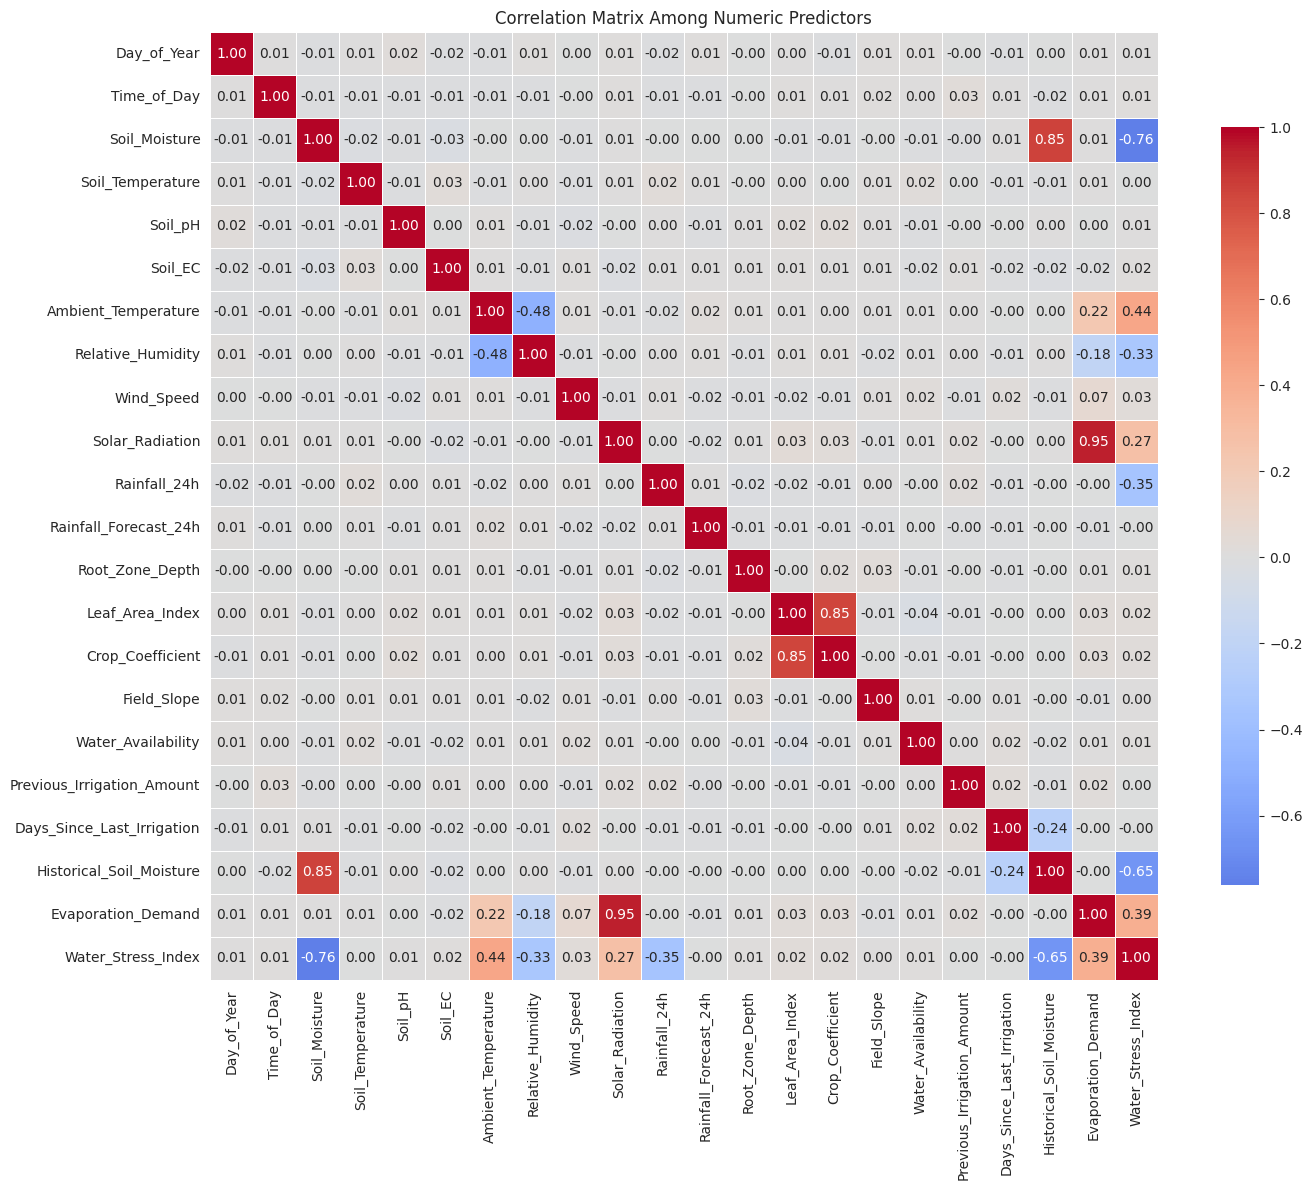

In [16]:
plt.figure(figsize=(15, 12))
corr_matrix = df[numeric_cols].corr()
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8})
plt.title("Correlation Matrix Among Numeric Predictors")
plt.tight_layout()
plt.show()

### 5. Basic visualization

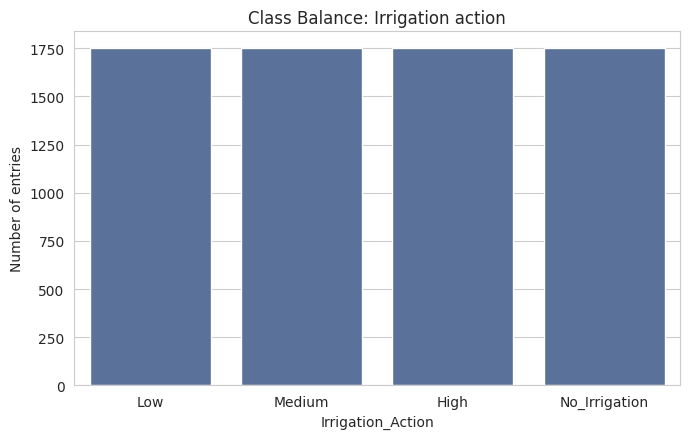

In [17]:
plt.figure(figsize=(7, 4.5))
sns.countplot(data=df, x=TARGET, order=["Low", "Medium", "High", "No_Irrigation"], color="#4F6EA4")
plt.title("Class Balance: Irrigation action")
plt.ylabel("Number of entries")
plt.tight_layout()
plt.show()

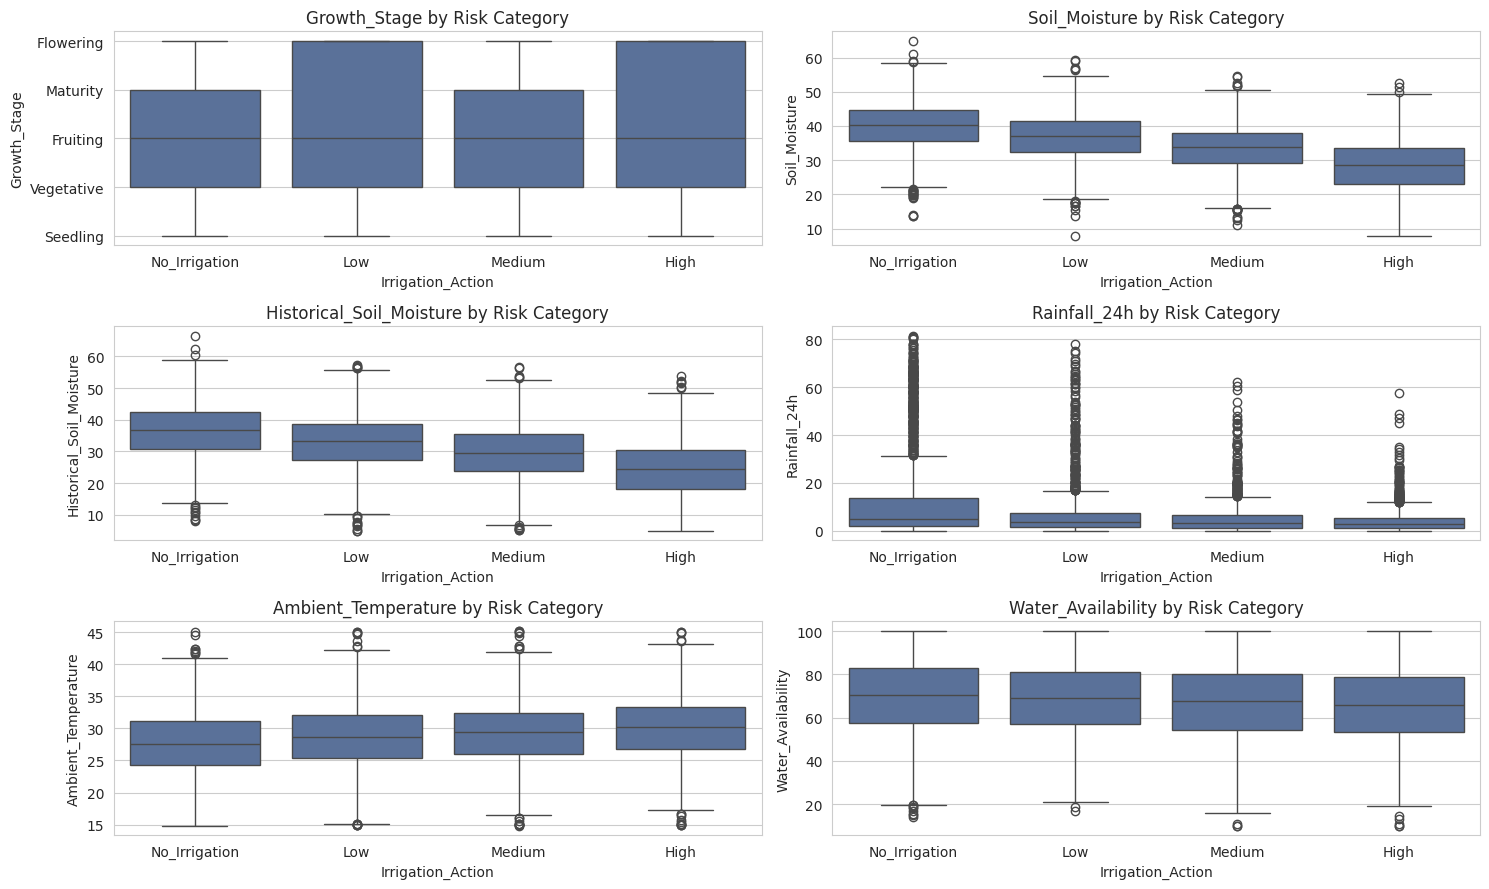

In [18]:
key_predictors = ["Growth_Stage", "Soil_Moisture", "Historical_Soil_Moisture", "Rainfall_24h", "Ambient_Temperature", "Water_Availability" ]

fig, axes = plt.subplots(3, 2, figsize=(15, 9))
for ax, col in zip(axes.flatten(), key_predictors):
    sns.boxplot(data=df, x=TARGET, y=col, order=["No_Irrigation","Low", "Medium", "High"], ax=ax, color="#4F6EA4")
    ax.set_title(f"{col} by Risk Category")
plt.tight_layout()
plt.show()

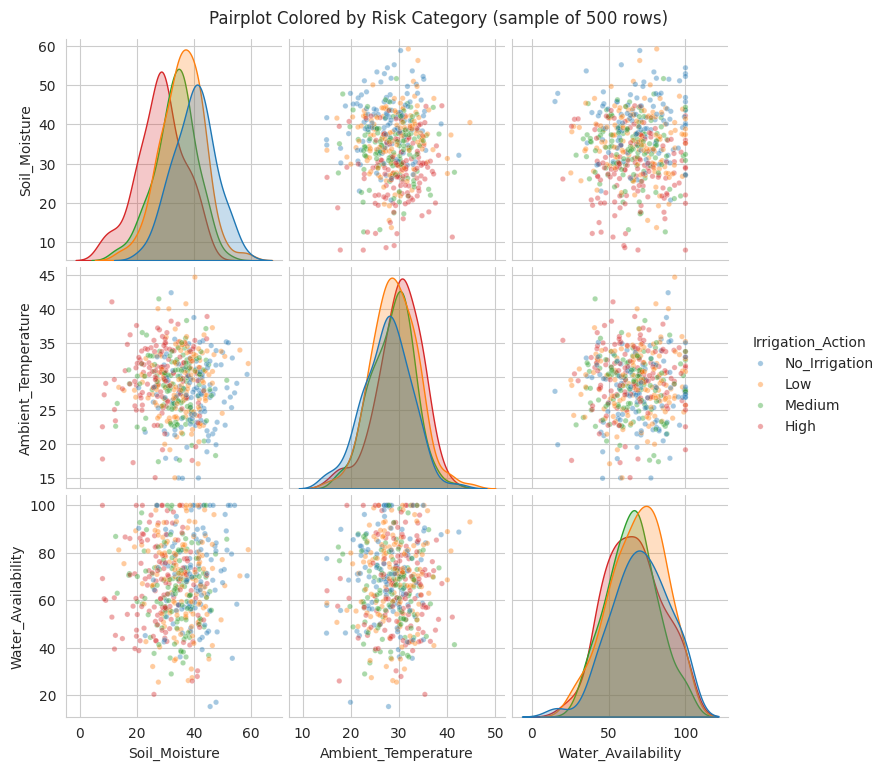

In [19]:
pairplot_cols = ["Soil_Moisture", "Ambient_Temperature", "Water_Availability", TARGET]

sns.pairplot(df[pairplot_cols].sample(500, random_state=RANDOM_STATE), hue=TARGET,
             hue_order=["No_Irrigation", "Low", "Medium", "High"], diag_kind="kde", plot_kws={"alpha": 0.4, "s": 15})
plt.suptitle("Pairplot Colored by Risk Category (sample of 500 rows)", y=1.02)
plt.show()

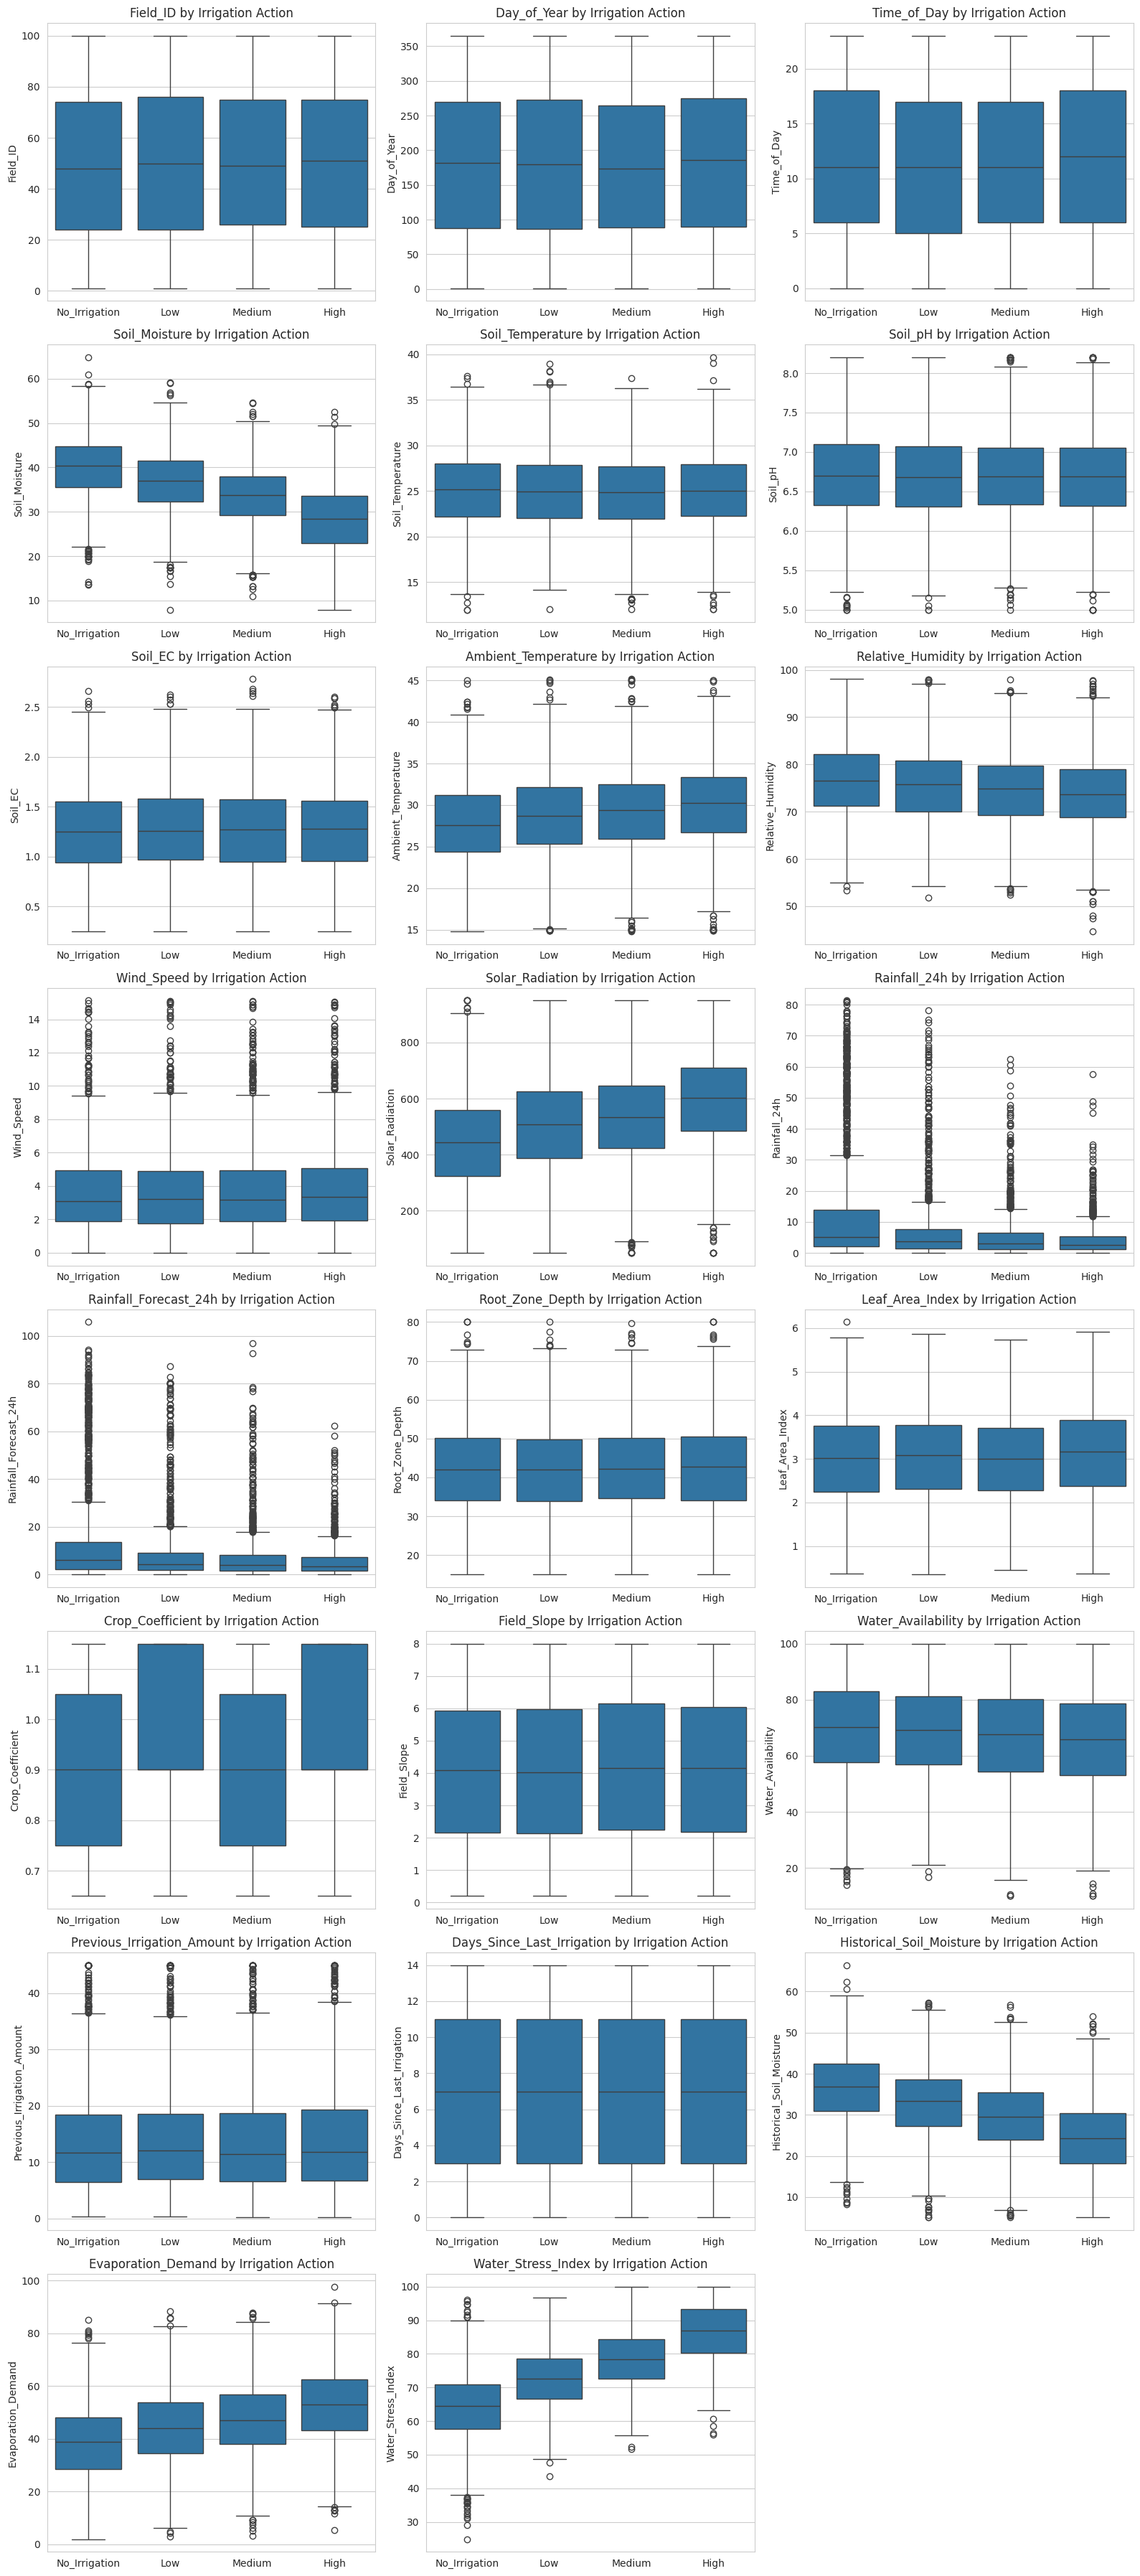

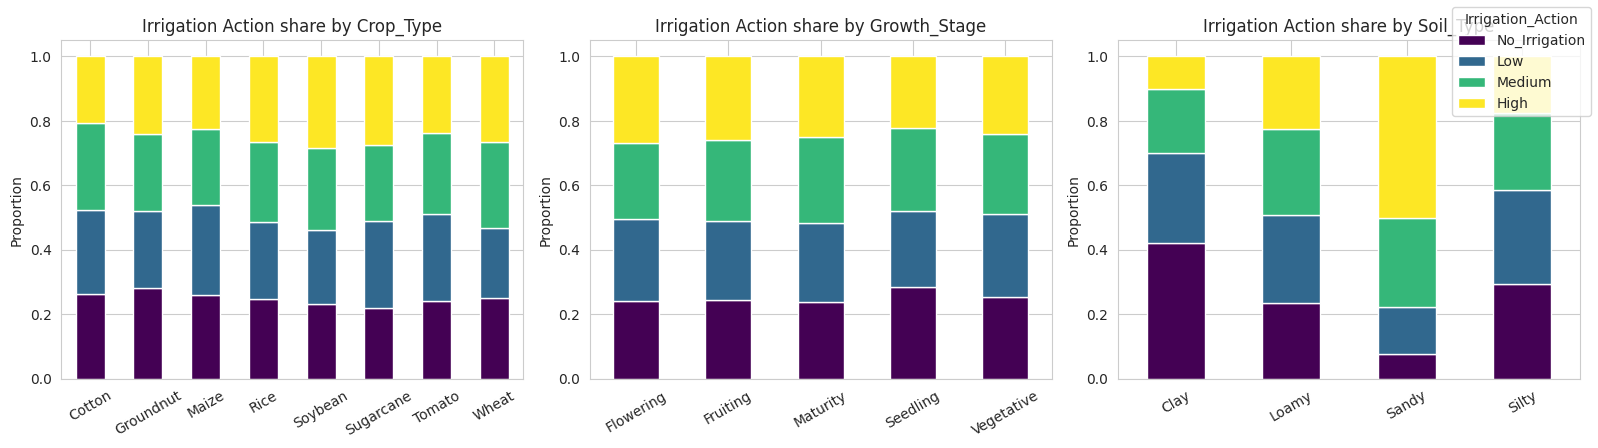

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns
import math

TARGET = "Irrigation_Action"
ACTION_ORDER = ["No_Irrigation", "Low", "Medium", "High"]   # logical order, not alphabetical

# Split features by dtype so each gets a suitable plot
features = [c for c in df.columns if c != TARGET]
num_cols = df[features].select_dtypes(include="number").columns.tolist()
cat_cols = [c for c in features if c not in num_cols]

# --- Numeric features: box plots per irrigation action ---
n_cols = 3
n_rows = math.ceil(len(num_cols) / n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 4.5 * n_rows))
axes = axes.flatten()

for ax, col in zip(axes, num_cols):
    sns.boxplot(data=df, x=TARGET, y=col, order=ACTION_ORDER, ax=ax)
    ax.set_title(f"{col} by Irrigation Action")
    ax.set_xlabel("")

# Hide empty subplots when the feature count isn't a multiple of n_cols
for ax in axes[len(num_cols):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

# --- Categorical features: share of each action within each category ---
n_rows = math.ceil(len(cat_cols) / n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 4.5 * n_rows))
axes = axes.flatten()

for ax, col in zip(axes, cat_cols):
    # Row-normalised crosstab: each bar sums to 1, so categories of different sizes are comparable
    ct = pd.crosstab(df[col], df[TARGET], normalize="index")[ACTION_ORDER]
    ct.plot(kind="bar", stacked=True, ax=ax, legend=False, colormap="viridis")
    ax.set_title(f"Irrigation Action share by {col}")
    ax.set_ylabel("Proportion")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=30)

for ax in axes[len(cat_cols):]:
    ax.set_visible(False)

# One shared legend instead of one per subplot
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, title=TARGET, loc="upper right")
plt.tight_layout()
plt.show()

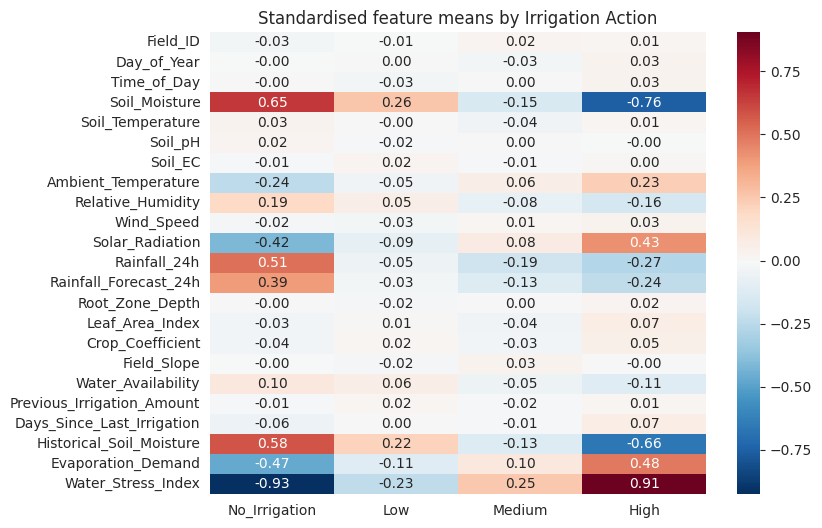

In [21]:
# Standardise numeric features so different units are comparable on one colour scale
z = df[num_cols].apply(lambda s: (s - s.mean()) / s.std())
z[TARGET] = df[TARGET]

# Mean z-score per class: rows = features, columns = actions
heat = z.groupby(TARGET)[num_cols].mean().T[ACTION_ORDER]

plt.figure(figsize=(8, 6))
sns.heatmap(heat, annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("Standardised feature means by Irrigation Action")
plt.xlabel("")
plt.show()

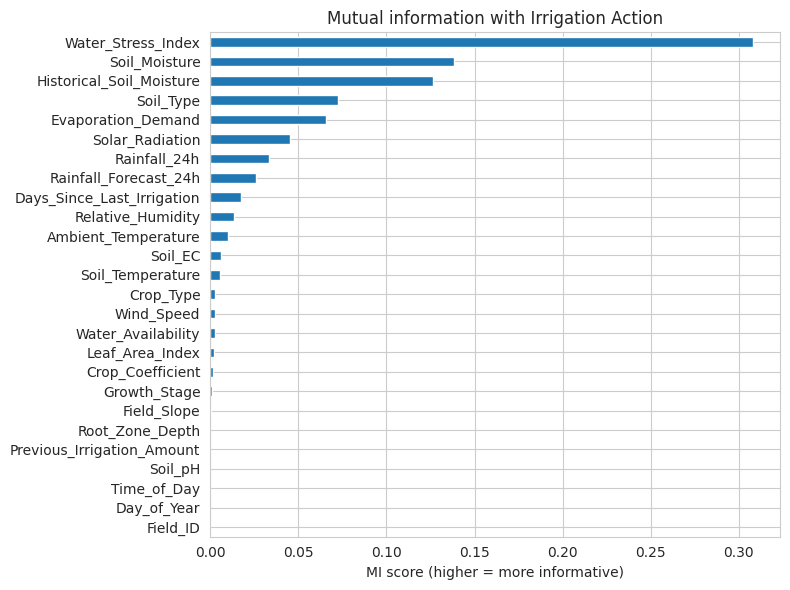

In [22]:
from sklearn.feature_selection import mutual_info_classif

X = df[features].copy()
# Encode categoricals as integer codes; MI needs numeric input
for c in cat_cols:
    X[c] = X[c].astype("category").cat.codes

# Temporarily impute missing values with their medians as mutual_info_classif cannot handle NaN
numeric_features = [col for col in features if col not in cat_cols]
X[numeric_features] = X[numeric_features].fillna(X[numeric_features].median())

discrete = [c in cat_cols for c in features]   # tell MI which columns are categorical
mi = mutual_info_classif(X, df[TARGET], discrete_features=discrete, random_state=42)

pd.Series(mi, index=features).sort_values().plot(kind="barh", figsize=(8, 6))
plt.title("Mutual information with Irrigation Action")
plt.xlabel("MI score (higher = more informative)")
plt.tight_layout()
plt.show()

## Train/Test Split

The goal is to have test data and train data that reflect the same distribution of classes as the while dataset.

In [23]:
from sklearn.model_selection import train_test_split

feature_cols = [c for c in df.columns if c not in ["Field_ID", TARGET]]

X = df[feature_cols].copy()
y = df[TARGET].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print(f"Training set: {X_train.shape[0]} rows")
print(f"Test set: {X_test.shape[0]} rows")
print("\nTraining class proportions:")
print(y_train.value_counts(normalize=True).round(3))
print("\nTest class proportions:")
print(y_test.value_counts(normalize=True).round(3))

Training set: 5600 rows
Test set: 1400 rows

Training class proportions:
Irrigation_Action
Medium           0.25
No_Irrigation    0.25
Low              0.25
High             0.25
Name: proportion, dtype: float64

Test class proportions:
Irrigation_Action
No_Irrigation    0.25
Medium           0.25
Low              0.25
High             0.25
Name: proportion, dtype: float64


## Feature selection

In [24]:
print(f"The starting features are {len(X_train.columns)}: {list(X_train.columns)}")

The starting features are 25: ['Crop_Type', 'Growth_Stage', 'Soil_Type', 'Day_of_Year', 'Time_of_Day', 'Soil_Moisture', 'Soil_Temperature', 'Soil_pH', 'Soil_EC', 'Ambient_Temperature', 'Relative_Humidity', 'Wind_Speed', 'Solar_Radiation', 'Rainfall_24h', 'Rainfall_Forecast_24h', 'Root_Zone_Depth', 'Leaf_Area_Index', 'Crop_Coefficient', 'Field_Slope', 'Water_Availability', 'Previous_Irrigation_Amount', 'Days_Since_Last_Irrigation', 'Historical_Soil_Moisture', 'Evaporation_Demand', 'Water_Stress_Index']


#### Chi-square test (categorical predictors)

The chi-square test requires non-negative integer-encoded categories and is sensitive to
low expected cell counts, so we apply it to label-encoded categorical columns.

- **Chi2 statistic:** Measures the strength of association between a feature
and the target. Higher values indicate a stronger relationship, meaning the
feature's distribution differs more between classes than would be expected by
chance.
- **p-value:** The probability of observing this association (or a stronger
one) if the feature were actually independent of the target. Low p-values
(typically **below 0.05**) suggest the association is unlikely to be due to random
noise, so the feature is probably informative.

**For feature selection:** We rank by `chi2_statistic`, **retain features with high
statistics and low p-values**, and discard features with high p-values (weak or
no real association).

In [25]:
from sklearn.feature_selection import chi2
from sklearn.preprocessing import LabelEncoder

categorical_train = X_train[categorical_cols].copy()
categorical_train_encoded = categorical_train.apply(lambda col: LabelEncoder().fit_transform(col.astype(str)))

chi2_stats, chi2_p_values = chi2(categorical_train_encoded, y_train)
chi2_summary = pd.DataFrame({
    "feature": categorical_cols,
    "chi2_statistic": chi2_stats,
    "p_value": chi2_p_values
}).sort_values("chi2_statistic", ascending=False)
chi2_summary.round(4)

,feature,chi2_statistic,p_value
2,Soil_Type,112.8676,0.0000
0,Crop_Type,15.8200,0.0012
1,Growth_Stage,6.2772,0.0989


### ANOVA F-test and Mutual Information (numeric predictors)

Mutual information captures non-linear dependence that the ANOVA F-test (a linear,
mean-difference test) can miss. Where the two disagree substantially on ranking, prefer
mutual information as a "sanity check", but do not discard a feature on the strength of
mutual information alone if it has a clear domain rationale.

| Situation                    | 	Interpretation                                                                        |
|------------------------------|---------------------------------------------------------------------------------------|
| High F-statistic AND high MI | Strong, likely linear signal; safe to retain                                          |
| Low F-statistic but high MI  | Non-linear relationship ANOVA missed; worth retaining, consider non-linear algorithms |
| High F-statistic but low MI  | Rare; check for a data leakage or coding issue                                        |
| Low on both                  | Weak candidate. Consider eliminating it.                                              |

In [26]:
from sklearn.feature_selection import SelectKBest, mutual_info_classif

numeric_train = X_train[numeric_cols].copy()
numeric_train_filled = numeric_train.fillna(numeric_train.median())

f_stats_train, p_values_train = f_classif(numeric_train_filled, y_train)
mi_scores = mutual_info_classif(numeric_train_filled, y_train, random_state=RANDOM_STATE)

numeric_selection_summary = pd.DataFrame({
    "feature": numeric_cols,
    "ANOVA_F": f_stats_train,
    "p_value": p_values_train,
    "mutual_info": mi_scores
}).sort_values("mutual_info", ascending=False)
numeric_selection_summary.round(4)

,feature,ANOVA_F,p_value,mutual_info
21,Water_Stress_Index,1548.0996,0.0000,0.3109
2,Soil_Moisture,691.8801,0.0000,0.1443
19,Historical_Soil_Moisture,497.4053,0.0000,0.1344
20,Evaporation_Demand,263.7314,0.0000,0.0710
9,Solar_Radiation,195.8217,0.0000,0.0423
10,Rainfall_24h,201.3156,0.0000,0.0357
11,Rainfall_Forecast_24h,103.0036,0.0000,0.0226
7,Relative_Humidity,35.6166,0.0000,0.0140
1,Time_of_Day,0.2090,0.8903,0.0089
15,Field_Slope,0.8561,0.4632,0.0065


In [27]:
numeric_selection_summary = numeric_selection_summary.copy()

numeric_selection_summary["ANOVA_rank"] = (
    numeric_selection_summary["ANOVA_F"]
    .rank(ascending=False, method="min")
)

numeric_selection_summary["MI_rank"] = (
    numeric_selection_summary["mutual_info"]
    .rank(ascending=False, method="min")
)

numeric_selection_summary["Average_rank"] = (
    numeric_selection_summary[["ANOVA_rank", "MI_rank"]]
    .mean(axis=1)
)

numeric_selection_summary = (
    numeric_selection_summary
    .sort_values("Average_rank")
    .reset_index(drop=True)
)

numeric_selection_summary.round(4)

,feature,ANOVA_F,p_value,mutual_info,ANOVA_rank,MI_rank,Average_rank
0,Water_Stress_Index,1548.0996,0.0000,0.3109,1.0,1.0,1.0
1,Soil_Moisture,691.8801,0.0000,0.1443,2.0,2.0,2.0
2,Historical_Soil_Moisture,497.4053,0.0000,0.1344,3.0,3.0,3.0
3,Evaporation_Demand,263.7314,0.0000,0.0710,4.0,4.0,4.0
4,Solar_Radiation,195.8217,0.0000,0.0423,6.0,5.0,5.5
5,Rainfall_24h,201.3156,0.0000,0.0357,5.0,6.0,5.5
6,Rainfall_Forecast_24h,103.0036,0.0000,0.0226,7.0,7.0,7.0
7,Relative_Humidity,35.6166,0.0000,0.0140,9.0,8.0,8.5
8,Ambient_Temperature,54.6137,0.0000,0.0061,8.0,12.0,10.0
9,Crop_Coefficient,3.8305,0.0094,0.0063,12.0,11.0,11.5


`Previous_Irrigation_Amount` has the lowest ANOVA_F and MI followed by `Water_Availability`

In [28]:
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate

# Use identical data and folds for both models
feature_to_test = "Days_Since_Last_Irrigation"

X_with = X_train.copy()
X_without = X_train.drop(columns=[feature_to_test])

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

def evaluate_model(X):
    numeric_cols = X.select_dtypes(include="number").columns
    categorical_cols = X.select_dtypes(
        include=["object", "category", "string"]
    ).columns

    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median"))
    ])

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ])

    preprocessor = ColumnTransformer([
        ("numeric", numeric_pipeline, numeric_cols),
        ("categorical", categorical_pipeline, categorical_cols)
    ])

    model = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=200,
            random_state=RANDOM_STATE,
            n_jobs=-1
        ))
    ])

    return cross_validate(
        model,
        X,
        y_train,
        cv=cv,
        scoring=["f1_macro", "balanced_accuracy"],
        n_jobs=-1
    )

results_with = evaluate_model(X_with)
results_without = evaluate_model(X_without)

In [29]:
comparison = pd.DataFrame({
    "With_feature": [
        results_with["test_f1_macro"].mean(),
        results_with["test_balanced_accuracy"].mean()
    ],
    "Without_feature": [
        results_without["test_f1_macro"].mean(),
        results_without["test_balanced_accuracy"].mean()
    ]
}, index=["Macro_F1", "Balanced_Accuracy"])

comparison["Difference"] = (
    comparison["With_feature"] - comparison["Without_feature"]
)

comparison.round(4)

,With_feature,Without_feature,Difference
Macro_F1,0.5110,0.5128,-0.0018
Balanced_Accuracy,0.5157,0.5184,-0.0027


### Recursive Feature Elimination (RFE)

RFE fits a model repeatedly, removing the weakest predictor(s) at each
iteration. We use a simple linear model as the estimator and rank all numeric
features (categorical features are handled separately via the encoding pipeline).

In [30]:
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import RFECV
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold

scaler_for_rfe = StandardScaler()
numeric_train_scaled = scaler_for_rfe.fit_transform(numeric_train_filled)

rfe_estimator = LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)

# `StratifiedKFold` is used rather than plain `KFold` because the target is
# categorical. Stratification ensures each fold preserves the original class
# proportions, which matters for classification, particularly if any class is
# imbalanced.

cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

rfecv_selector = RFECV(
    estimator=rfe_estimator,
    step=1,
    cv=cv_strategy,
    scoring="accuracy",
    min_features_to_select=1
)
rfecv_selector.fit(numeric_train_scaled, y_train)

rfecv_ranking = pd.DataFrame({
    "feature": numeric_cols,
    "selected": rfecv_selector.support_,
    "rank": rfecv_selector.ranking_
}).sort_values("rank")

print(f"Optimal number of features: {rfecv_selector.n_features_}")
rfecv_ranking

Optimal number of features: 12


,feature,selected,rank
2,Soil_Moisture,True,1
7,Relative_Humidity,True,1
6,Ambient_Temperature,True,1
4,Soil_pH,True,1
13,Leaf_Area_Index,True,1
11,Rainfall_Forecast_24h,True,1
10,Rainfall_24h,True,1
9,Solar_Radiation,True,1
20,Evaporation_Demand,True,1
21,Water_Stress_Index,True,1


Here again `Previous_Irrigation_Amoount` was flagged.

Tree based feature importance

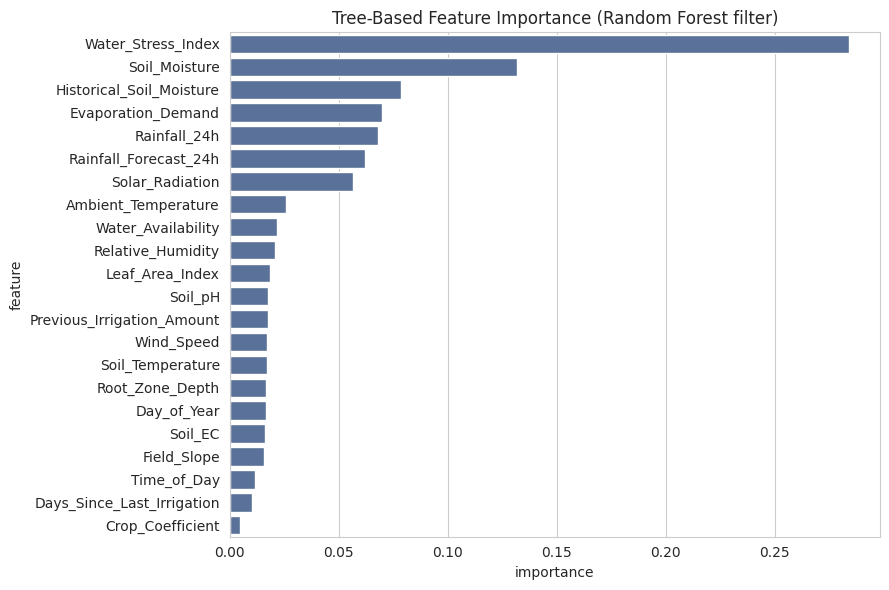

In [31]:
from sklearn.ensemble import RandomForestClassifier

rf_filter = RandomForestClassifier(random_state=RANDOM_STATE, n_estimators=300, max_depth=8)
rf_filter.fit(numeric_train_filled, y_train)

tree_importance = pd.DataFrame({
    "feature": numeric_cols,
    "importance": rf_filter.feature_importances_
}).sort_values("importance", ascending=False)

plt.figure(figsize=(9, 6))
sns.barplot(data=tree_importance, y="feature", x="importance", color="#4F6EA4")
plt.title("Tree-Based Feature Importance (Random Forest filter)")
plt.tight_layout()
plt.show()

In [32]:
# df = df.drop(columns=['Previous_Irrigation_Amount', 'Historical_Soil_Moisture', 'Days_Since_Last_Irrigation', 'Water_Availability', 'Growth_Stage'])

In [33]:
# print(f"The features remaining are {len(X_train.columns)}: {list(X_train.columns)}")

Data Preprocessing

In [34]:
cat_candidates = ["Crop_Type", "Growth_Stage", "Soil_Type", "Water_Availability", "Evaporation_Demand"]

for col in cat_candidates:
    # dtype tells you numeric vs text; unique values give you the exact spellings
    print(f"{col:22s} {str(X_train[col].dtype):8s} {sorted(X_train[col].dropna().unique())[:15]}")

print("\nMissing values per feature (train):")
print(X_train[FEATURES].isna().sum())

Crop_Type              object   ['Cotton', 'Groundnut', 'Maize', 'Rice', 'Soybean', 'Sugarcane', 'Tomato', 'Wheat']
Growth_Stage           object   ['Flowering', 'Fruiting', 'Maturity', 'Seedling', 'Vegetative']
Soil_Type              object   ['Clay', 'Loamy', 'Sandy', 'Silty']
Water_Availability     float64  [np.float64(10.0), np.float64(10.66), np.float64(10.87), np.float64(13.06), np.float64(13.92), np.float64(14.37), np.float64(15.8), np.float64(16.75), np.float64(16.89), np.float64(17.3), np.float64(17.74), np.float64(17.78), np.float64(18.33), np.float64(18.56), np.float64(18.75)]
Evaporation_Demand     float64  [np.float64(2.0), np.float64(2.88), np.float64(2.93), np.float64(3.6), np.float64(3.79), np.float64(4.31), np.float64(4.35), np.float64(4.74), np.float64(5.0), np.float64(5.04), np.float64(5.45), np.float64(6.31), np.float64(6.35), np.float64(6.79), np.float64(6.81)]

Missing values per feature (train):


NameError: name 'FEATURES' is not defined

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline as SkPipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, PowerTransformer, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
from imblearn.pipeline import Pipeline as ImbPipeline   # NOT sklearn's: skips resampling at predict time
from imblearn.over_sampling import SMOTE

# =============================================================================
# 1. Column groups
# =============================================================================
nominal_cols = ["Crop_Type", "Soil_Type"]                     # no natural order -> one-hot

ordinal_cols = ["Growth_Stage"]                               # crop life cycle order -> ordinal

history_cols = ["Historical_Soil_Moisture",                   # structurally missing on a farmer's
                "Days_Since_Last_Irrigation",                 # first submission -> median + indicator
                "Previous_Irrigation_Amount"]

numeric_cols = ["Soil_Moisture", "Ambient_Temperature", "Evaporation_Demand", "Water_Availability"]

# One category list per ordinal column, in the same order as ordinal_cols
ordinal_orders = [
    ["Seedling", "Vegetative", "Flowering", "Fruiting", "Maturity"],   # Growth_Stage
]

skewed_cols = ["Rainfall_24h", "Rainfall_Forecast_24h"]

# =============================================================================
# 2. Guards: catch label typos or a forgotten feature before anything is fitted
# =============================================================================

for col, order in zip(ordinal_cols, ordinal_orders):
    unexpected = set(X_train[col].dropna().unique()) - set(order)
    assert not unexpected, f"{col} has labels not in your order list: {unexpected}"

all_assigned = nominal_cols + ordinal_cols + history_cols + numeric_cols + skewed_cols
assert sorted(all_assigned) == sorted(FEATURES), f"Mismatch: {set(FEATURES) ^ set(all_assigned)}"

# =============================================================================
# 3. Sub-pipelines (one per column group)
# =============================================================================
nominal_pipeline = SkPipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),       # unseen crop at inference -> all zeros
])

ordinal_pipeline = SkPipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("ordinal", OrdinalEncoder(categories=ordinal_orders,
                               handle_unknown="use_encoded_value",
                               unknown_value=-1)),            # unseen stage -> -1 instead of crashing
])

history_pipeline = SkPipeline(steps=[
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),  # adds a 0/1 "was missing" column
    ("scaler", StandardScaler()),
])

skewed_pipeline = SkPipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("power", PowerTransformer(method="yeo-johnson")),  # standardize=True by default
])

numeric_pipeline = SkPipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),            # Soil_Moisture & Rainfall_24h gaps
    ("scaler", StandardScaler()),                             # needed for LogReg/KNN/SVM comparisons
])

# =============================================================================
# 4. Combine into one preprocessor
# =============================================================================
preprocessor = ColumnTransformer(transformers=[
    ("nominal", nominal_pipeline, nominal_cols),
    ("ordinal", ordinal_pipeline, ordinal_cols),
    ("history", history_pipeline, history_cols),
    ("numeric", numeric_pipeline, numeric_cols),
], remainder="drop")                                          # anything not listed is excluded

# =============================================================================
# 5. Preview (sanity check only; the real fit happens inside CV below)
# =============================================================================
X_train_preview = preprocessor.fit_transform(X_train, y_train)
print(f"Shape after preprocessing: {X_train_preview.shape}")  # expect (n_rows, 23)
for name in preprocessor.get_feature_names_out():
    print("  ", name)

# =============================================================================
# 6. Full modelling pipeline: preprocess -> resample -> classify
# =============================================================================
rf_pipeline = ImbPipeline(steps=[
    ("preprocessor", preprocessor),
    ("smote", SMOTE(random_state=RANDOM_STATE)),              # train folds only; skipped at predict()
    ("model", RandomForestClassifier(n_estimators=300, max_depth=8,
                                     random_state=RANDOM_STATE)),
])


Distribution transformation.

In [ ]:
# Box-Cox / Yeo-Johnson demonstration on skewed predictors
# Yeo-Johnson is used because Rainfall_24h and Rainfall_Forecast_24h contain zeros (Box-Cox requires > 0)
skewed_cols = ["Rainfall_24h", "Rainfall_Forecast_24h", "Previous_Irrigation_Amount"]

yeojohnson_demo = X_train[skewed_cols].copy()
yeojohnson_transformer = PowerTransformer(method="yeo-johnson", standardize=False)
yeojohnson_result = pd.DataFrame(
    yeojohnson_transformer.fit_transform(yeojohnson_demo),   # fit on training data only
    columns=skewed_cols
)

fig, axes = plt.subplots(len(skewed_cols), 2, figsize=(12, 4.5 * len(skewed_cols)))

for i, col in enumerate(skewed_cols):
    sns.histplot(yeojohnson_demo[col], kde=True, ax=axes[i, 0], color="#4F6EA4")
    axes[i, 0].set_title(f"{col}: Before Yeo-Johnson")

    sns.histplot(yeojohnson_result[col], kde=True, ax=axes[i, 1], color="#4F6EA4")
    axes[i, 1].set_title(f"{col}: After Yeo-Johnson")

plt.tight_layout()
plt.show()

# Before/after skewness side by side
skewness_comparison = pd.DataFrame({
    "skewness_before": yeojohnson_demo.skew(),
    "skewness_after": yeojohnson_result.skew(),
    "lambda": yeojohnson_transformer.lambdas_,
}).round(2)
skewness_comparison

## Machine Learning Pipeline and Cross-Validation


In [ ]:
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB

models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=15),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE, max_depth=6),
    "Random Forest": RandomForestClassifier(random_state=RANDOM_STATE, n_estimators=300, max_depth=8),
    "Gradient Boosting": GradientBoostingClassifier(random_state=RANDOM_STATE, n_estimators=200, max_depth=3),
    "Support Vector Machine": SVC(probability=True, random_state=RANDOM_STATE),
    "Naive Bayes": GaussianNB()
}

stratified_kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_results = {}

for name, model in models.items():
    pipeline = ImbPipeline(steps=[
        ("preprocessor", preprocessor),
        ("smote", SMOTE(random_state=RANDOM_STATE)),
        ("model", model)
    ])
    scores = cross_val_score(pipeline, X_train, y_train, cv=stratified_kfold,
                              scoring="f1_macro", n_jobs=-1)
    cv_results[name] = scores
    print(f"{name:25s} F1-macro: {scores.mean():.4f}  (+/- {scores.std():.4f})")

In [ ]:
cv_results_df = pd.DataFrame(cv_results)
plt.figure(figsize=(11, 5))
sns.boxplot(data=cv_results_df, color="#4F6EA4")
plt.ylabel("Stratified Cross-Validated F1-macro")
plt.title("Stratified 5-Fold Cross-Validation: F1-macro by Model (with SMOTE)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.model_selection import cross_validate

for name in ["Logistic Regression", "Random Forest", "Naive Bayes"]:
    pipeline = ImbPipeline(steps=[
        ("preprocessor", preprocessor),
        ("smote", SMOTE(random_state=RANDOM_STATE)),
        ("model", models[name]),
    ])
    # return_train_score=True gives the score on the data each fold was trained on
    results = cross_validate(pipeline, X_train, y_train, cv=stratified_kfold,
                             scoring="f1_macro", return_train_score=True, n_jobs=-1)
    print(f"{name:20s} train: {results['train_score'].mean():.4f} | "
          f"validation: {results['test_score'].mean():.4f}")

confusion matrix

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# 1. Define class labels
class_labels = sorted(y_test.unique())

# 2. Fit the best Logistic Regression pipeline from your tuning/modeling steps
logreg_pipeline = ImbPipeline(steps=[
    ("preprocessor", preprocessor),
    ("smote", SMOTE(random_state=RANDOM_STATE)),
    ("model", LogisticRegression(C=0.1, max_iter=2000, random_state=RANDOM_STATE))
])
logreg_pipeline.fit(X_train, y_train)
y_pred_logreg = logreg_pipeline.predict(X_test)

# 3. Fit the Random Forest pipeline
rf_pipeline.fit(X_train, y_train)
y_pred_rf = rf_pipeline.predict(X_test)

# 4. Plot the confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, (name, y_pred) in zip(axes, [("Random Forest", y_pred_rf), ("Logistic Regression", y_pred_logreg)]):
    cm = confusion_matrix(y_test, y_pred, labels=class_labels)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_labels)
    disp.plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"Confusion Matrix: {name}")
plt.tight_layout()
plt.show()

Hyper param tuning

In [ ]:
from sklearn.model_selection import GridSearchCV
from imblearn.over_sampling import SMOTE, ADASYN
from imblearn.under_sampling import RandomUnderSampler

tuning_pipeline = ImbPipeline(steps=[
    ("preprocessor", preprocessor),
    ("resampler", SMOTE(random_state=RANDOM_STATE)),
    ("model", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
])

param_grid = {
    # "passthrough" = no resampling, which tests whether resampling helps at all
    "resampler": [
        SMOTE(random_state=RANDOM_STATE),
        ADASYN(random_state=RANDOM_STATE),
        RandomUnderSampler(random_state=RANDOM_STATE),
        "passthrough",
    ],
    "model__C": [0.01, 0.1, 1, 10, 100],          # smaller C = stronger regularization
    "model__class_weight": [None, "balanced"],    # alternative to resampling for imbalance
}

grid_search = GridSearchCV(
    tuning_pipeline,
    param_grid,
    cv=stratified_kfold,
    scoring="f1_macro",
    n_jobs=-1,
    verbose=0
)

grid_search.fit(X_train, y_train)

print(f"Best tuned model: {grid_search.best_estimator_.named_steps['model']}")
print(f"Best parameters: {grid_search.best_params_}")
print(f"Best CV F1-macro: {grid_search.best_score_:.4f}")

explainability

In [ ]:
# Fit a binary framing for clean odds-ratio interpretation: High risk vs. not High risk
y_train_binary = (y_train == "High").astype(int)
y_test_binary = (y_test == "High").astype(int)

logreg_binary_pipeline = ImbPipeline(steps=[
    ("preprocessor", preprocessor),
    ("smote", SMOTE(random_state=RANDOM_STATE)),
    ("model", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
])
logreg_binary_pipeline.fit(X_train, y_train_binary)

feature_names_out = preprocessor.get_feature_names_out()
log_odds = logreg_binary_pipeline.named_steps["model"].coef_[0]
odds_ratios = np.exp(log_odds)

odds_ratio_df = pd.DataFrame({
    "feature": feature_names_out,
    "log_odds_coefficient": log_odds,
    "odds_ratio": odds_ratios
}).sort_values("odds_ratio", ascending=False)

print("Interpretation: an odds ratio > 1 means the feature increases the odds of 'High' risk;")
print("an odds ratio < 1 means it decreases the odds, holding other features constant.")
odds_ratio_df

tree based feature importance

In [ ]:
final_feature_names = preprocessor.get_feature_names_out()
rf_importance = pd.DataFrame({
    "feature": final_feature_names,
    "importance": rf_pipeline.named_steps["model"].feature_importances_
}).sort_values("importance", ascending=False)

plt.figure(figsize=(9, 7))
sns.barplot(data=rf_importance.head(15), y="feature", x="importance", color="#4F6EA4")
plt.title("Random Forest Feature Importance (Top 15)")
plt.tight_layout()
plt.show()

In [ ]:
import shap

# Fix: Assign the best estimator from the GridSearch to best_tuned_model
best_tuned_model = grid_search.best_estimator_

X_test_transformed = best_tuned_model.named_steps["preprocessor"].transform(X_test)
X_train_transformed = best_tuned_model.named_steps["preprocessor"].transform(X_train)
fitted_model = best_tuned_model.named_steps["model"]

print(f"Model classes in order: {fitted_model.classes_}")
print(f"Selected model type: {type(fitted_model).__name__}")
high_class_index = list(fitted_model.classes_).index("High")

# TreeExplainer only supports tree-based models (Random Forest, Gradient Boosting,
# Decision Tree). Since Stage 10's grid search can select ANY model family as "best",
# the explainer must adapt to whichever model type actually won.
# Non-tree models fall back to a model-agnostic explainer, which is slower
# (it queries the model many times), so it runs on a smaller sample.
tree_based_types = ("RandomForestClassifier", "GradientBoostingClassifier", "DecisionTreeClassifier")

if type(fitted_model).__name__ in tree_based_types:
    explainer = shap.TreeExplainer(fitted_model)
    shap_values = explainer.shap_values(X_test_transformed[:300])
    if isinstance(shap_values, list):
        shap_values_high_class = shap_values[high_class_index]
    else:
        shap_values_high_class = shap_values[:, :, high_class_index]
    plot_sample = X_test_transformed[:300]
else:
    background = shap.sample(X_train_transformed, 100, random_state=RANDOM_STATE)
    explainer = shap.Explainer(fitted_model.predict_proba, background)
    shap_explanation = explainer(X_test_transformed[:100])  # smaller subset -- this path is much slower
    shap_values_high_class = shap_explanation[..., high_class_index].values
    plot_sample = X_test_transformed[:100]

shap.summary_plot(shap_values_high_class, plot_sample,
                   feature_names=final_feature_names, show=False)
plt.title(f"SHAP Summary: Drivers of 'High' Risk Classification ({type(fitted_model).__name__})")
plt.tight_layout()
plt.show()

LIME

In [ ]:
%pip install lime

In [ ]:
from lime.lime_tabular import LimeTabularExplainer

lime_explainer = LimeTabularExplainer(
    training_data=best_tuned_model.named_steps["preprocessor"].transform(X_train),
    feature_names=list(final_feature_names),
    class_names=list(best_tuned_model.named_steps["model"].classes_),
    mode="classification",
    random_state=RANDOM_STATE,
)

# Fix: Dynamically choose the first available index in the test set to avoid index mismatches
target_index = X_test.index[0]

if target_index not in X_test.index:
    raise ValueError(
        f"Applicant index {target_index} is not in the test set for this split "
        f"(it may have landed in the training set, or may not exist in the dataset at all)."
    )

position = X_test.index.get_loc(target_index)
sample_instance = X_test_transformed[position]

lime_explanation = lime_explainer.explain_instance(
    sample_instance,
    best_tuned_model.named_steps["model"].predict_proba,
    num_features=8,
)

print(f"Explaining prediction for test applicant index {target_index}")
print(f"Actual risk category: {y_test.loc[target_index]}")
for feature, weight in lime_explanation.as_list():
    print(f"  {feature:65s} {weight:+.4f}")

Model persistence

In [ ]:
import joblib
import os
from datetime import datetime

# Automatically picks the best tuned pipeline from GridSearchCV
final_pipeline = grid_search.best_estimator_

# (Optional) refit on the full training data to be explicit;
# GridSearchCV already does this when refit=True (the default)
final_pipeline.fit(X_train, y_train)

# Ensure the model folder exists
model_dir = "./model"
os.makedirs(model_dir, exist_ok=True)   # no error if it already exists

# Build the filename from the model name and a timestamp
# The timestamp prevents overwriting a previous run and keeps model versions traceable
model_name = final_pipeline.named_steps["model"].__class__.__name__
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
model_filename = f"{timestamp}_{model_name}_irrigation_action_classifier.joblib".lower()
model_path = os.path.normpath(os.path.join(model_dir, model_filename))

joblib.dump(final_pipeline, model_path)
print("Selected model:", model_name)
print(f"✅ Best pipeline (preprocessing + model) saved to: {model_path}")

In [ ]:
import pandas as pd

# Load using the path from Step 1. Hardcoding a filename breaks once the timestamp changes.
loaded_pipeline = joblib.load(model_path)

# One farmer submission, using the same 12 features the model was trained on
# Category spellings must match the dataset exactly (check with df_cols_keep[col].unique())
new_submission = pd.DataFrame([{
    "Crop_Type": "rice",
    "Growth_Stage": "Vegetative",
    "Soil_Type": "Loamy",
    "Soil_Moisture": 12.5,                 # farmer input
    "Water_Availability": 10,              # farmer input
    "Ambient_Temperature": 28.4,           # weather API
    "Rainfall_24h": 0.0,                   # weather API
    "Rainfall_Forecast_24h": 1.2,          # weather API
    "Evaporation_Demand": 5.1,             # weather API
    "Previous_Irrigation_Amount": 15.0,    # system irrigation log
    "Days_Since_Last_Irrigation": 4,       # system irrigation log
    "Historical_Soil_Moisture": 30.0,      # previous submission
}])

predicted_action = loaded_pipeline.predict(new_submission)[0]
predicted_proba = loaded_pipeline.predict_proba(new_submission)[0]

print(f"Recommended irrigation action: {predicted_action}")
print("\nClass probabilities:")
for cls, proba in zip(loaded_pipeline.classes_, predicted_proba):
    print(f"  {cls}: {proba:.3f}")

# One input row should produce exactly one prediction
print(f"\nInput rows: {len(new_submission)} -> predictions: {len(loaded_pipeline.predict(new_submission))}")

In [ ]:
import requests
import pandas as pd

# Farm location: replace with the farmer's coordinates (Nairobi used as an example)
LAT, LON = -1.2921, 36.8219

def fetch_weather_features(lat, lon):
    """Return the 4 weather features the model expects, from Open-Meteo."""
    params = {
        "latitude": lat,
        "longitude": lon,
        "current": "temperature_2m",                               # Ambient_Temperature
        "hourly": "precipitation,et0_fao_evapotranspiration",      # rainfall + ET0
        "past_hours": 24,          # window ends at the current hour
        "forecast_hours": 24,      # window starts after the current hour
        "timezone": "auto",        # local time, so 'now' and the hourly times line up
    }
    resp = requests.get("https://api.open-meteo.com/v1/forecast", params=params, timeout=10)
    resp.raise_for_status()        # stop on HTTP errors (e.g. a bad parameter returns 400)
    data = resp.json()

    # Hourly arrays -> DataFrame indexed by timestamp
    hourly = pd.DataFrame(data["hourly"])
    hourly["time"] = pd.to_datetime(hourly["time"])
    now = pd.to_datetime(data["current"]["time"])

    past = hourly[hourly["time"] <= now]     # previous 24 hours
    future = hourly[hourly["time"] > now]    # next 24 hours

    return {
        "Ambient_Temperature": data["current"]["temperature_2m"],
        "Rainfall_24h": round(past["precipitation"].sum(), 2),
        "Rainfall_Forecast_24h": round(future["precipitation"].sum(), 2),
        "Evaporation_Demand": round(future["et0_fao_evapotranspiration"].sum(), 2),  # mm over the next 24h
    }

weather = fetch_weather_features(LAT, LON)
print("Weather features:", weather)

# Farmer inputs + system records, merged with live weather
new_submission = pd.DataFrame([{
    "Crop_Type": "rice",
    "Growth_Stage": "Vegetative",
    "Soil_Type": "sandy",
    "Soil_Moisture": 22.5,                 # farmer input
    "Water_Availability": 60.0,            # farmer input
    "Previous_Irrigation_Amount": 15.0,    # system irrigation log
    "Days_Since_Last_Irrigation": 4,       # system irrigation log
    "Historical_Soil_Moisture": 30.0,      # previous submission
    **weather,                             # the 4 Open-Meteo features
}])[FEATURES]                              # reorder columns to match training

# Flag weather values that fall outside what the model saw in training
for col in weather:
    lo, hi = df[col].min(), df[col].max()
    if not lo <= weather[col] <= hi:
        print(f"⚠️ {col}={weather[col]} is outside the training range [{lo}, {hi}]")

predicted_action = loaded_pipeline.predict(new_submission)[0]
predicted_proba = loaded_pipeline.predict_proba(new_submission)[0]

print(f"\nRecommended irrigation action: {predicted_action}")
for cls, proba in zip(loaded_pipeline.classes_, predicted_proba):
    print(f"  {cls}: {proba:.3f}")

weather api python testing

In [ ]:
!pip install openmeteo-requests
!pip install requests-cache retry-requests numpy pandas

In [ ]:
import openmeteo_requests

import pandas as pd
import requests_cache
from retry_requests import retry

# Setup the Open-Meteo API client with cache and retry on error
cache_session = requests_cache.CachedSession('.cache', expire_after = 3600)
retry_session = retry(cache_session, retries = 5, backoff_factor = 0.2)
openmeteo = openmeteo_requests.Client(session = retry_session)

# Make sure all required weather variables are listed here
# The order of variables in hourly or daily is important to assign them correctly below
url = "https://api.open-meteo.com/v1/forecast"
params = {
	"latitude": -1.2833,
	"longitude": 36.8167,
	"daily": "rain_sum",
	"hourly": ["temperature_2m", "rain", "soil_temperature_0cm", "soil_temperature_6cm", "soil_temperature_18cm", "soil_temperature_54cm", "soil_moisture_0_to_1cm", "soil_moisture_1_to_3cm", "soil_moisture_3_to_9cm", "soil_moisture_9_to_27cm", "soil_moisture_27_to_81cm", "wind_speed_10m", "weather_code", "evapotranspiration", "temperature_80m", "direct_radiation", "direct_radiation_instant"],
	"current": ["temperature_2m", "precipitation", "rain"],
	"timezone": "auto",
	"past_days": 1,
	"forecast_days": 1,
}
responses = openmeteo.weather_api(url, params = params)

# Process first location. Add a for-loop for multiple locations or weather models
response = responses[0]
print(f"Coordinates: {response.Latitude()}°N {response.Longitude()}°E")
print(f"Elevation: {response.Elevation()} m asl")
print(f"Timezone: {response.Timezone()}{response.TimezoneAbbreviation()}")
print(f"Timezone difference to GMT+0: {response.UtcOffsetSeconds()}s")

# Process current data. The order of variables needs to be the same as requested.
current = response.Current()
current_temperature_2m = current.Variables(0).Value()
current_precipitation = current.Variables(1).Value()
current_rain = current.Variables(2).Value()

print(f"\nCurrent time: {current.Time()}")
print(f"Current temperature_2m: {current_temperature_2m}")
print(f"Current precipitation: {current_precipitation}")
print(f"Current rain: {current_rain}")

# Process hourly data. The order of variables needs to be the same as requested.
hourly = response.Hourly()
hourly_temperature_2m = hourly.Variables(0).ValuesAsNumpy()
hourly_rain = hourly.Variables(1).ValuesAsNumpy()
hourly_soil_temperature_0cm = hourly.Variables(2).ValuesAsNumpy()
hourly_soil_temperature_6cm = hourly.Variables(3).ValuesAsNumpy()
hourly_soil_temperature_18cm = hourly.Variables(4).ValuesAsNumpy()
hourly_soil_temperature_54cm = hourly.Variables(5).ValuesAsNumpy()
hourly_soil_moisture_0_to_1cm = hourly.Variables(6).ValuesAsNumpy()
hourly_soil_moisture_1_to_3cm = hourly.Variables(7).ValuesAsNumpy()
hourly_soil_moisture_3_to_9cm = hourly.Variables(8).ValuesAsNumpy()
hourly_soil_moisture_9_to_27cm = hourly.Variables(9).ValuesAsNumpy()
hourly_soil_moisture_27_to_81cm = hourly.Variables(10).ValuesAsNumpy()
hourly_wind_speed_10m = hourly.Variables(11).ValuesAsNumpy()
hourly_weather_code = hourly.Variables(12).ValuesAsNumpy()
hourly_evapotranspiration = hourly.Variables(13).ValuesAsNumpy()
hourly_temperature_80m = hourly.Variables(14).ValuesAsNumpy()
hourly_direct_radiation = hourly.Variables(15).ValuesAsNumpy()
hourly_direct_radiation_instant = hourly.Variables(16).ValuesAsNumpy()

hourly_data = {
	"date": pd.date_range(
		start = pd.to_datetime(hourly.Time(), unit = "s", utc = True),
		end =  pd.to_datetime(hourly.TimeEnd(), unit = "s", utc = True),
		freq = pd.Timedelta(seconds = hourly.Interval()),
		inclusive = "left"
	).tz_convert(response.Timezone().decode())
}

hourly_data["temperature_2m"] = hourly_temperature_2m
hourly_data["rain"] = hourly_rain
hourly_data["soil_temperature_0cm"] = hourly_soil_temperature_0cm
hourly_data["soil_temperature_6cm"] = hourly_soil_temperature_6cm
hourly_data["soil_temperature_18cm"] = hourly_soil_temperature_18cm
hourly_data["soil_temperature_54cm"] = hourly_soil_temperature_54cm
hourly_data["soil_moisture_0_to_1cm"] = hourly_soil_moisture_0_to_1cm
hourly_data["soil_moisture_1_to_3cm"] = hourly_soil_moisture_1_to_3cm
hourly_data["soil_moisture_3_to_9cm"] = hourly_soil_moisture_3_to_9cm
hourly_data["soil_moisture_9_to_27cm"] = hourly_soil_moisture_9_to_27cm
hourly_data["soil_moisture_27_to_81cm"] = hourly_soil_moisture_27_to_81cm
hourly_data["wind_speed_10m"] = hourly_wind_speed_10m
hourly_data["weather_code"] = hourly_weather_code
hourly_data["evapotranspiration"] = hourly_evapotranspiration
hourly_data["temperature_80m"] = hourly_temperature_80m
hourly_data["direct_radiation"] = hourly_direct_radiation
hourly_data["direct_radiation_instant"] = hourly_direct_radiation_instant

hourly_dataframe = pd.DataFrame(data = hourly_data)
print("\nHourly data\n", hourly_dataframe)

# Process daily data. The order of variables needs to be the same as requested.
daily = response.Daily()
daily_rain_sum = daily.Variables(0).ValuesAsNumpy()

daily_data = {
	"date": pd.date_range(
		start = pd.to_datetime(daily.Time(), unit = "s", utc = True),
		end =  pd.to_datetime(daily.TimeEnd(), unit = "s", utc = True),
		freq = pd.Timedelta(seconds = daily.Interval()),
		inclusive = "left"
	).tz_convert(response.Timezone().decode())
}

daily_data["rain_sum"] = daily_rain_sum

daily_dataframe = pd.DataFrame(data = daily_data)
print("\nDaily data\n", daily_dataframe)


In [ ]:
import pandas as pd

# Display the hourly weather data as a formatted pandas DataFrame
print("=== Hourly Weather Data DataFrame ===")
display(hourly_dataframe.head(10))

# Display the daily weather data as a formatted pandas DataFrame
print("\n=== Daily Weather Data DataFrame ===")
display(daily_dataframe)

In [ ]:
import pandas as pd
from google.colab import files

# Define the filename
excel_filename = 'weather_data_export.xlsx'

# Make copies to avoid modifying original dataframes
hourly_export = hourly_dataframe.copy()
daily_export = daily_dataframe.copy()

# Strip timezone awareness so Excel can save them cleanly
hourly_export['date'] = hourly_export['date'].dt.tz_localize(None)
daily_export['date'] = daily_export['date'].dt.tz_localize(None)

# Write both hourly and daily dataframes into a single Excel file on separate sheets
with pd.ExcelWriter(excel_filename, engine='openpyxl') as writer:
    hourly_export.to_excel(writer, sheet_name='Hourly Weather', index=False)
    daily_export.to_excel(writer, sheet_name='Daily Weather', index=False)

print(f'✅ Excel file created successfully: {excel_filename}')

# Trigger the download helper in Google Colab
files.download(excel_filename)